In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [53]:
train = pd.read_csv("/content/data_date_train.csv")
print("Training dataset shape:", train.shape)
print("\nTraining dataset:")
print(train.head())

Training dataset shape: (21862, 4)

Training dataset:
         Date     Country Status  AQI Value
0  2023-03-30  Azerbaijan   Good         40
1  2026-02-05     Reunion   Good         21
2  2022-08-25  Costa Rica   Good         43
3  2026-06-18     Estonia   Good         16
4  2026-01-22      Brunei   Good         17


In [54]:
test = pd.read_csv("/content/data_date_test.csv")
print("Test dataset shape:", test.shape)
print("\nTest dataset:")
print(test.head())

Test dataset shape: (5465, 4)

Test dataset:
         Date     Country Status  AQI Value
0  2022-08-14      Latvia   Good         25
1  2023-08-03  Uzbekistan   Good         30
2  2024-09-26    Cambodia   Good         21
3  2023-03-30      Belize   Good         29
4  2024-07-25     Albania   Good         24


In [55]:
print("TRAINING DATA INFORMATION")
train.info()

print("\nTEST DATA INFORMATION")
test.info()

TRAINING DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21862 entries, 0 to 21861
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Date       21862 non-null  object
 1   Country    21862 non-null  object
 2   Status     21862 non-null  object
 3   AQI Value  21862 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 683.3+ KB

TEST DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5465 entries, 0 to 5464
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Date       5465 non-null   object
 1   Country    5465 non-null   object
 2   Status     5465 non-null   object
 3   AQI Value  5465 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 170.9+ KB


In [56]:
print("Numerical summary:")
print(train.describe().round(2))

print("\nSummary of all columns:")
print(train.describe(include="all").T)

Numerical summary:
       AQI Value
count   21862.00
mean       62.56
std        50.47
min         1.00
25%        29.00
50%        52.00
75%        81.00
max       963.00

Summary of all columns:
             count unique         top   freq       mean        std  min   25%  \
Date         21862    208  2022-07-22    339        NaN        NaN  NaN   NaN   
Country      21862    142     Iceland    187        NaN        NaN  NaN   NaN   
Status       21862      6        Good  10566        NaN        NaN  NaN   NaN   
AQI Value  21862.0    NaN         NaN    NaN  62.559876  50.465794  1.0  29.0   

            50%   75%    max  
Date        NaN   NaN    NaN  
Country     NaN   NaN    NaN  
Status      NaN   NaN    NaN  
AQI Value  52.0  81.0  963.0  


In [57]:
print("Missing values in training data:")
print(train.isnull().sum())


Missing values in training data:
Date         0
Country      0
Status       0
AQI Value    0
dtype: int64


In [58]:
print("\nMissing values in test data:")
print(test.isnull().sum())


Missing values in test data:
Date         0
Country      0
Status       0
AQI Value    0
dtype: int64


In [59]:
print("Training missing percentages:")
print((train.isnull().mean() * 100).round(2))

Training missing percentages:
Date         0.0
Country      0.0
Status       0.0
AQI Value    0.0
dtype: float64


In [60]:
print("\nTest missing percentages:")
print((test.isnull().mean() * 100).round(2))


Test missing percentages:
Date         0.0
Country      0.0
Status       0.0
AQI Value    0.0
dtype: float64


In [61]:
print("Duplicate rows in training:", train.duplicated().sum())
print("Duplicate training dates:", train["Date"].duplicated().sum())

Duplicate rows in training: 187
Duplicate training dates: 21654


In [62]:
print("Duplicate rows in test:", test.duplicated().sum())
print("Duplicate test dates:", test["Date"].duplicated().sum())

Duplicate rows in test: 6
Duplicate test dates: 5257


In [63]:
print("Status counts:")
print(train["Status"].value_counts().sort_index())
print("\nStatus percentages:")
print((train["Status"].value_counts(normalize=True).sort_index() * 100).round(2))

Status counts:
Status
Good                              10566
Hazardous                           106
Moderate                           7848
Unhealthy                           902
Unhealthy for Sensitive Groups     2237
Very Unhealthy                      203
Name: count, dtype: int64

Status percentages:
Status
Good                              48.33
Hazardous                          0.48
Moderate                          35.90
Unhealthy                          4.13
Unhealthy for Sensitive Groups    10.23
Very Unhealthy                     0.93
Name: proportion, dtype: float64


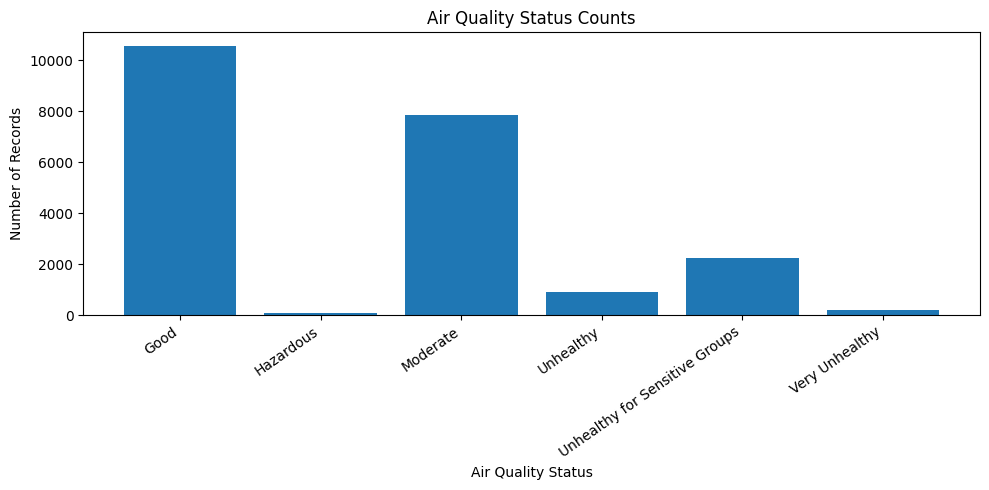

In [64]:
status_counts = train["Status"].value_counts().sort_index()
plt.figure(figsize=(10, 5))
plt.bar(status_counts.index, status_counts.values)
plt.title("Air Quality Status Counts")
plt.xlabel("Air Quality Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

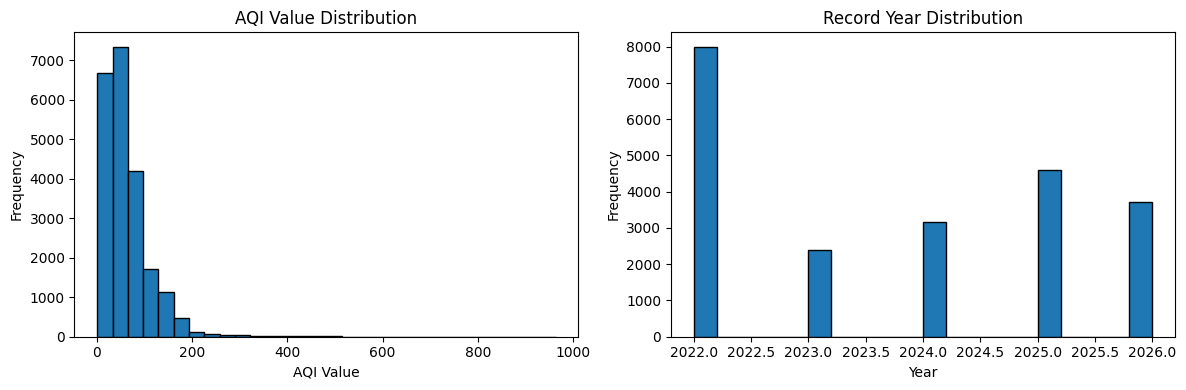

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train["AQI Value"].dropna(), bins=30, edgecolor="black")
axes[0].set_title("AQI Value Distribution")
axes[0].set_xlabel("AQI Value")
axes[0].set_ylabel("Frequency")

axes[1].hist(pd.to_datetime(train["Date"], errors="coerce").dropna().map(lambda x: x.year), bins=20, edgecolor="black")
axes[1].set_title("Record Year Distribution")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

In [66]:
print("Median AQI value:", train["AQI Value"].median())
print("Mean AQI value:", train["AQI Value"].mean())
print("Minimum AQI value:", train["AQI Value"].min())
print("Maximum AQI value:", train["AQI Value"].max())

Median AQI value: 52.0
Mean AQI value: 62.559875583203734
Minimum AQI value: 1
Maximum AQI value: 963


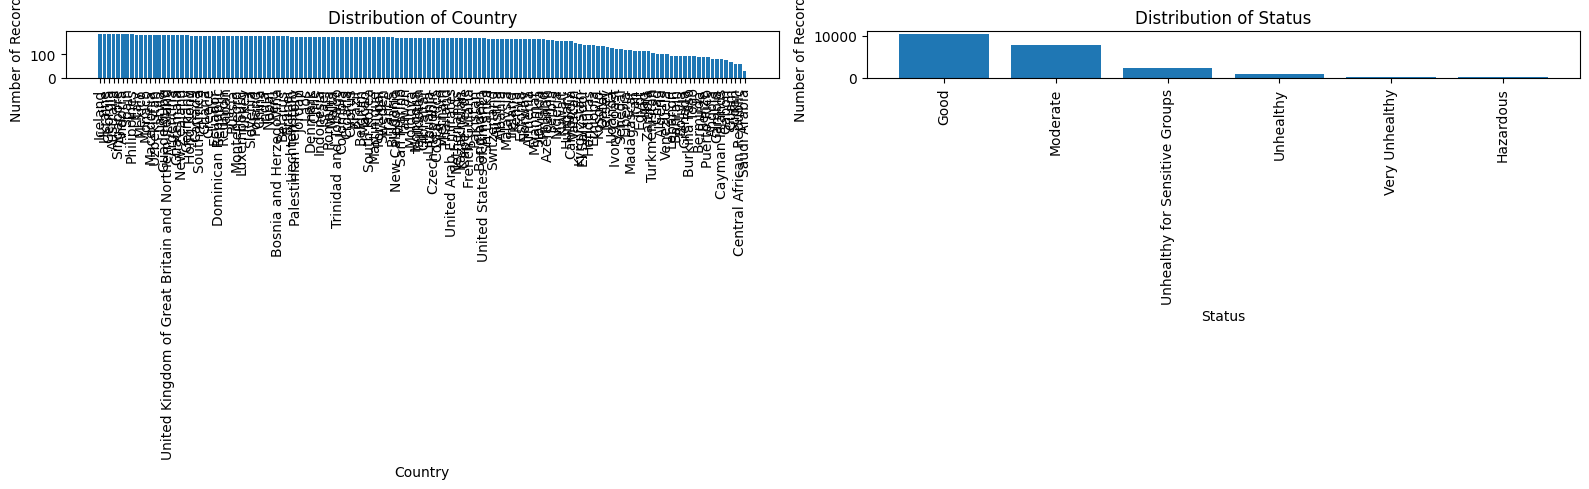

In [67]:
categorical_columns = ["Country", "Status"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, column in zip(axes, categorical_columns):
    counts = train[column].fillna("Missing").value_counts()
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Records")
    ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

In [68]:
print("Country counts:")
print(train["Country"].value_counts())
print("\nStatus counts:")
print(train["Status"].value_counts(dropna=False))

Country counts:
Country
Iceland                     187
Ukraine                     185
Georgia                     185
Australia                   185
Singapore                   185
                           ... 
Gabon                        73
Guam                         66
Sudan                        60
Central African Republic     60
Saudi Arabia                 27
Name: count, Length: 142, dtype: int64

Status counts:
Status
Good                              10566
Moderate                           7848
Unhealthy for Sensitive Groups     2237
Unhealthy                           902
Very Unhealthy                      203
Hazardous                           106
Name: count, dtype: int64


Country
India             233.22
China             176.82
Iraq              156.06
Iran              151.37
Bangladesh        143.08
                   ...  
Puerto Rico        12.93
Bermuda            12.91
Brunei             12.18
Cayman Islands     11.41
Guam                3.45
Name: AQI Value, Length: 142, dtype: float64


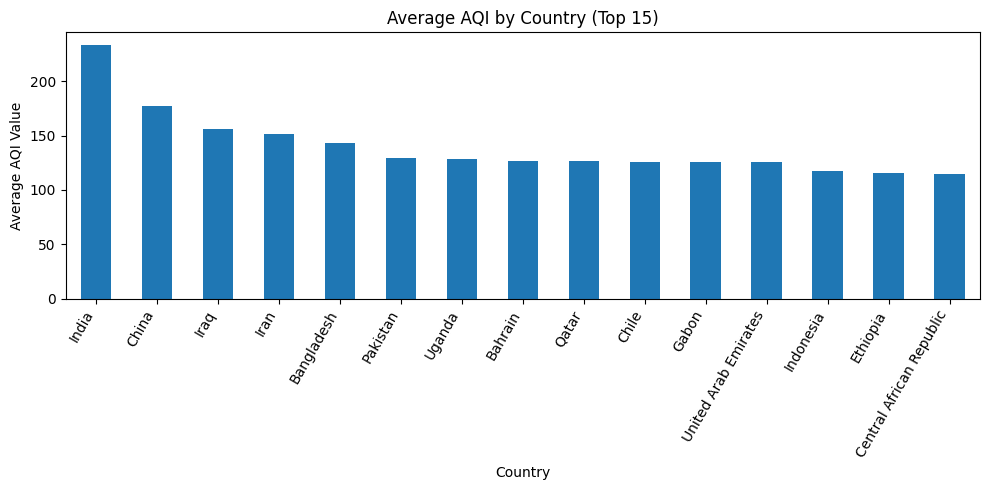

Status
Hazardous                         408.27
Very Unhealthy                    242.22
Unhealthy                         167.50
Unhealthy for Sensitive Groups    121.96
Moderate                           70.49
Good                               28.21
Name: AQI Value, dtype: float64


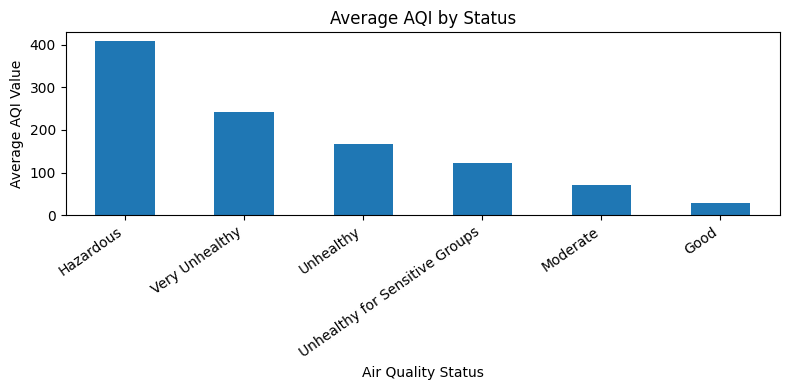

In [69]:
country_aqi = train.groupby("Country")["AQI Value"].mean().sort_values(ascending=False)
print(country_aqi.round(2))
country_aqi.head(15).plot(kind="bar", figsize=(10, 5))
plt.title("Average AQI by Country (Top 15)")
plt.xlabel("Country")
plt.ylabel("Average AQI Value")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

status_aqi = train.groupby("Status")["AQI Value"].mean().sort_values(ascending=False)
print(status_aqi.round(2))
status_aqi.plot(kind="bar", figsize=(8, 4))
plt.title("Average AQI by Status")
plt.xlabel("Air Quality Status")
plt.ylabel("Average AQI Value")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


           AQI Value
AQI Value        1.0


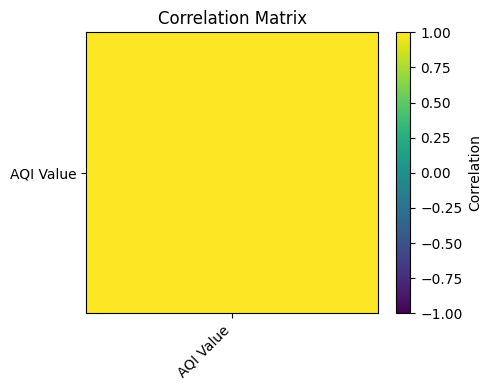

In [70]:
numeric_columns = ["AQI Value"]
correlation = train[numeric_columns].corr()
print(correlation.round(2))
plt.figure(figsize=(5, 4))
plt.imshow(correlation, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.index)), correlation.index)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [71]:
train_clean = train.copy()
test_clean = test.copy()

In [72]:
aqI_median = train["AQI Value"].median()
print("AQI value median:", aqI_median)

AQI value median: 52.0


In [73]:
train_clean["AQI Value"] = train_clean["AQI Value"].fillna(aqI_median)
test_clean["AQI Value"] = test_clean["AQI Value"].fillna(aqI_median)

for df in [train_clean, test_clean]:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df["Date"] = df["Date"].fillna(train_clean["Date"].mode()[0])
    df["Country"] = df["Country"].fillna(train_clean["Country"].mode()[0])
    df["Status"] = df["Status"].fillna(train_clean["Status"].mode()[0])

print("\nMissing values after cleaning — train:")
print(train_clean.isnull().sum())
print("\nMissing values after cleaning — test:")
print(test_clean.isnull().sum())


Missing values after cleaning — train:
Date         0
Country      0
Status       0
AQI Value    0
dtype: int64

Missing values after cleaning — test:
Date         0
Country      0
Status       0
AQI Value    0
dtype: int64


In [74]:
for df in [train_clean, test_clean]:
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Day"] = df["Date"].dt.day
    print(train_clean[["Date", "Country", "Year", "Month", "Day", "AQI Value", "Status"]].head(10))

        Date     Country  Year  Month  Day  AQI Value Status
0 2023-03-30  Azerbaijan  2023      3   30         40   Good
1 2026-02-05     Reunion  2026      2    5         21   Good
2 2022-08-25  Costa Rica  2022      8   25         43   Good
3 2026-06-18     Estonia  2026      6   18         16   Good
4 2026-01-22      Brunei  2026      1   22         17   Good
5 2026-08-20    Slovakia  2026      8   20         35   Good
6 2022-09-12     Finland  2022      9   12         24   Good
7 2026-05-21  Martinique  2026      5   21         23   Good
8 2025-07-17     Vietnam  2025      7   17         47   Good
9 2022-07-23    Portugal  2022      7   23         26   Good
        Date     Country  Year  Month  Day  AQI Value Status
0 2023-03-30  Azerbaijan  2023      3   30         40   Good
1 2026-02-05     Reunion  2026      2    5         21   Good
2 2022-08-25  Costa Rica  2022      8   25         43   Good
3 2026-06-18     Estonia  2026      6   18         16   Good
4 2026-01-22      Brunei

In [75]:
print("Cleaned training shape:", train_clean.shape)
print("Cleaned test shape:", test_clean.shape)
print("Missing cells in training:", train_clean.isnull().sum().sum())
print("Missing cells in test:", test_clean.isnull().sum().sum())
print("Status column in training:", "Status" in train_clean.columns)
print("Status column in test:", "Status" in test_clean.columns)

Cleaned training shape: (21862, 7)
Cleaned test shape: (5465, 7)
Missing cells in training: 0
Missing cells in test: 0
Status column in training: True
Status column in test: True


In [76]:
train_clean.to_csv("data_date_train_cleaned.csv", index=False)
test_clean.to_csv("data_date_test_cleaned.csv", index=False)
print("Cleaned training dataset saved.")
print("Cleaned test dataset saved.")


Cleaned training dataset saved.
Cleaned test dataset saved.


In [77]:
X_train = train_clean.drop(columns=["Status", "Date"])
y_train = train_clean["Status"]
X_test = test_clean.drop(columns=["Status", "Date"])
y_test = test_clean["Status"]
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)
print("Testing features:", X_test.shape)
print("Testing target:", y_test.shape)


Training features: (21862, 5)
Training target: (21862,)
Testing features: (5465, 5)
Testing target: (5465,)
